<a href="https://colab.research.google.com/github/gguex/ISH_ressources_cours_ML/blob/main/TP08c_corrige.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP 8 : Corrigé de l'exercice

La recette du cours 8 appliquée aux données `contraceptive.tsv` : prédire la méthode de contraception à partir de neuf variables.

In [1]:
from pathlib import Path
import copy

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
# PyTorch : les tenseurs, les couches des réseaux, et les outils pour les données
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
# Pour séparer et standardiser les données
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
# La référence de la partie 1 : la régression logistique
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Le même style de graphiques qu'aux TP précédents
sns.set_theme(style="whitegrid", palette="colorblind")

In [2]:
# Connexion à Google Drive sur Colab ; dossier local sinon
try:
    from google.colab import drive
except ImportError:
    data_path = Path("data") / "TP8"
else:
    drive.mount("/content/drive")
    data_path = Path("/content/drive/MyDrive/Colab Notebooks/data/TP8")

Mounted at /content/drive


In [3]:
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(42)
print(device)

cpu


Les fonctions du TP :

In [4]:
def compute_scores(outputs_true, outputs_pred, average="binary"):
    return {
        "Exactitude": accuracy_score(outputs_true, outputs_pred),
        "Précision": precision_score(outputs_true, outputs_pred,
                                     average=average, zero_division=0),
        "Rappel": recall_score(outputs_true, outputs_pred, average=average),
        "F1": f1_score(outputs_true, outputs_pred, average=average),
    }


def plot_confusion(outputs_true, outputs_pred):
    confusion = pd.crosstab(outputs_true, outputs_pred,
                            rownames=["Vraie classe"],
                            colnames=["Classe prédite"])
    fig, ax = plt.subplots(figsize=(4, 3), layout="constrained")
    sns.heatmap(confusion, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    plt.show()

In [5]:
def make_loader(inputs_std, outputs, shuffle):
    """Tenseurs, TensorDataset, puis DataLoader en mini-batchs de 64."""
    X = torch.tensor(inputs_std, dtype=torch.float32)
    y = torch.tensor(outputs.to_numpy(), dtype=torch.long)
    return DataLoader(TensorDataset(X, y), batch_size=64, shuffle=shuffle)

In [6]:
class MLP(nn.Module):
    def __init__(self, n_inputs, n_hidden, n_classes, dropout=0.2):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_inputs, n_hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(n_hidden, n_hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(n_hidden, n_classes))       # renvoie des logits

    def forward(self, x):
        return self.layers(x)

In [7]:
def train_one_epoch(model, loader, loss_fn, optimizer):
    """Entraîne le réseau sur tous les mini-batchs ; renvoie la perte moyenne."""
    model.train()                                  # active le dropout
    total_loss = 0.0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        logits = model(X)              # 1. passage avant
        loss = loss_fn(logits, y)      # 2. perte
        loss.backward()                # 3. gradients
        optimizer.step()               # 4. mise à jour
        optimizer.zero_grad()          # remise à zéro des gradients
        total_loss += loss.item() * len(y)         # pondérée par la taille du mini-batch
    return total_loss / len(loader.dataset)


def evaluate(model, loader, loss_fn):
    """Renvoie la perte moyenne et les classes prédites, sans suivre les gradients."""
    model.eval()                                   # désactive le dropout
    total_loss = 0.0
    predictions = []
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            logits = model(X)
            total_loss += loss_fn(logits, y).item() * len(y)
            predictions.append(logits.argmax(dim=1).cpu())
    return total_loss / len(loader.dataset), torch.cat(predictions).numpy()

In [8]:
def train_model(model, train_loader, valid_loader, loss_fn, optimizer, n_epochs):
    """Entraîne le réseau et garde les paramètres de la meilleure epoch.
    Renvoie les pertes de chaque epoch dans un DataFrame."""
    history = []
    best_valid_loss = float("inf")
    for epoch in range(1, n_epochs + 1):
        train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer)
        valid_loss, _ = evaluate(model, valid_loader, loss_fn)
        history.append({"epoch": epoch, "Entraînement": train_loss, "Validation": valid_loss})
        if valid_loss < best_valid_loss:
            best_valid_loss = valid_loss
            best_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return pd.DataFrame(history).set_index("epoch")

In [9]:
def plot_history(history, title):
    """Courbes d'apprentissage, avec la meilleure epoch en pointillés."""
    best_epoch = history["Validation"].idxmin()
    fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
    sns.lineplot(data=history, ax=ax)
    ax.axvline(best_epoch, color="black", linestyle="--")
    ax.set(xlabel="Epoch", ylabel="Perte",
           title=f"{title} : meilleure epoch {best_epoch}")
    plt.show()

### 1. Les données

In [10]:
data = pd.read_csv(data_path / "contraceptive.tsv", sep="\t")
inputs = data.drop(columns=["target"])
outputs = data["target"] - 1        # 0 : aucune, 1 : longue durée, 2 : courte durée
print(outputs.value_counts().sort_index())

inputs_dev, inputs_test, outputs_dev, outputs_test = \
    train_test_split(inputs, outputs, test_size=0.2, stratify=outputs,
                     random_state=42)
inputs_train, inputs_valid, outputs_train, outputs_valid = \
    train_test_split(inputs_dev, outputs_dev, test_size=0.25, stratify=outputs_dev,
                     random_state=42)

scaler = StandardScaler().fit(inputs_train)
inputs_train_std = scaler.transform(inputs_train)
inputs_valid_std = scaler.transform(inputs_valid)
inputs_test_std = scaler.transform(inputs_test)
print(len(inputs_train), len(inputs_valid), len(inputs_test))

target
0    629
1    333
2    511
Name: count, dtype: int64
883 295 295


### 2. Les mini-batchs

In [11]:
train_loader = make_loader(inputs_train_std, outputs_train, shuffle=True)
valid_loader = make_loader(inputs_valid_std, outputs_valid, shuffle=False)
test_loader = make_loader(inputs_test_std, outputs_test, shuffle=False)
n_inputs = inputs.shape[1]

### 3. Le réseau du cours

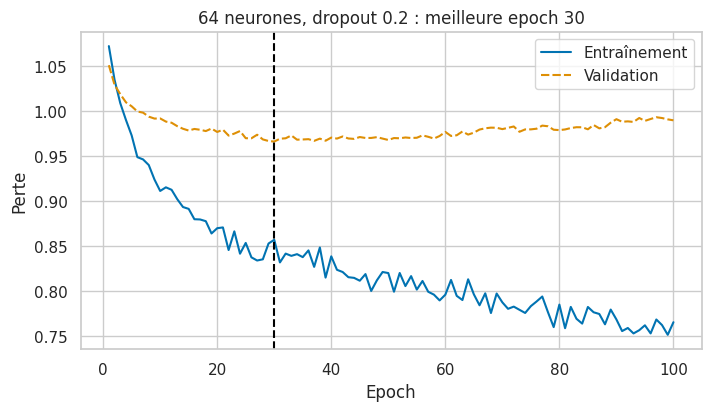

In [12]:
loss_fn = nn.CrossEntropyLoss()

torch.manual_seed(42)
model = MLP(n_inputs=n_inputs, n_hidden=64, n_classes=3).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
history = train_model(model, train_loader, valid_loader, loss_fn, optimizer, n_epochs=100)
plot_history(history, "64 neurones, dropout 0.2")

Les deux pertes baissent pendant une trentaine d'epochs, et la meilleure epoch est la 30e. Ensuite, la perte d'entraînement continue de baisser, mais la perte de validation remonte lentement : le réseau surapprend à partir d'une trentaine d'epochs. Grâce à la meilleure epoch, `model` garde les paramètres de l'epoch 30.

### 4. Deux réseaux plus grands

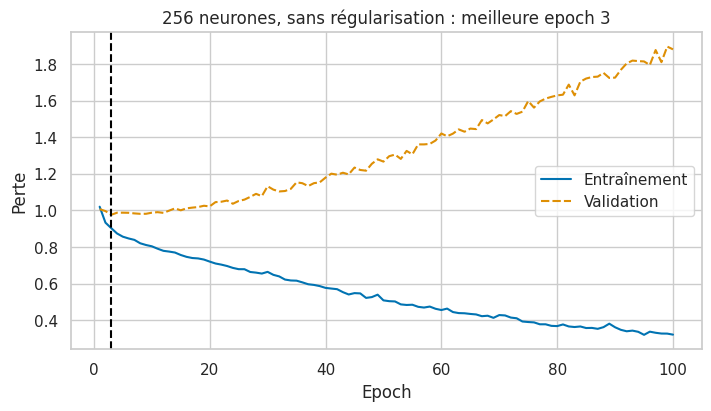

In [13]:
torch.manual_seed(42)
big_model = MLP(n_inputs=n_inputs, n_hidden=256, n_classes=3, dropout=0.0).to(device)
big_optimizer = torch.optim.Adam(big_model.parameters(), lr=0.001)
big_history = train_model(big_model, train_loader, valid_loader, loss_fn, big_optimizer,
                          n_epochs=100)
plot_history(big_history, "256 neurones, sans régularisation")

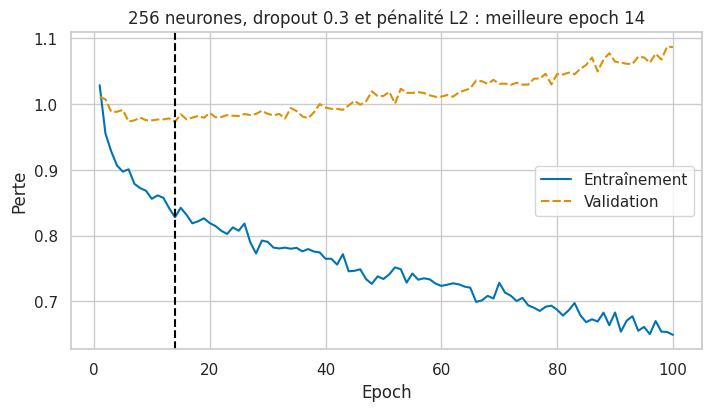

In [14]:
torch.manual_seed(42)
reg_model = MLP(n_inputs=n_inputs, n_hidden=256, n_classes=3, dropout=0.3).to(device)
reg_optimizer = torch.optim.Adam(reg_model.parameters(), lr=0.001, weight_decay=1e-3)
reg_history = train_model(reg_model, train_loader, valid_loader, loss_fn, reg_optimizer,
                          n_epochs=100)
plot_history(reg_history, "256 neurones, dropout 0.3 et pénalité L2")

In [15]:
networks = {"64 neurones, dropout 0.2": model,
            "256 neurones, sans régularisation": big_model,
            "256 neurones, dropout 0.3 et pénalité L2": reg_model}
valid_scores = {}
for name, network in networks.items():
    valid_loss, outputs_valid_pred = evaluate(network, valid_loader, loss_fn)
    valid_scores[name] = {"Perte de validation": valid_loss,
                          "F1 macro de validation": f1_score(outputs_valid, outputs_valid_pred,
                                                             average="macro")}
pd.DataFrame(valid_scores).T.round(3)

,Perte de validation,F1 macro de validation
"64 neurones, dropout 0.2",0.966,0.517
"256 neurones, sans régularisation",0.976,0.507
"256 neurones, dropout 0.3 et pénalité L2",0.973,0.487


Sans régularisation, le grand réseau surapprend presque tout de suite : sa meilleure epoch est la 3e, et sa perte de validation double ensuite. La régularisation retarde le surapprentissage, avec une meilleure epoch à 14, sans l'empêcher : avec 883 femmes d'entraînement, près de 70 000 paramètres restent beaucoup trop. Le réseau du cours a la plus petite perte et le meilleur F1 macro de validation (0.517) : on le retient.

In [16]:
chosen_model = model

### 5. Le test

In [17]:
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(inputs_train_std, outputs_train)
outputs_log_test = log_reg.predict(inputs_test_std)

_, outputs_mlp_test = evaluate(chosen_model, test_loader, loss_fn)

pd.DataFrame({"Régression logistique": compute_scores(outputs_test, outputs_log_test,
                                                      average="macro"),
              "Perceptron multicouche": compute_scores(outputs_test, outputs_mlp_test,
                                                       average="macro")}).T.round(3)

,Exactitude,Précision,Rappel,F1
Régression logistique,0.525,0.51,0.496,0.499
Perceptron multicouche,0.590,0.57,0.568,0.569


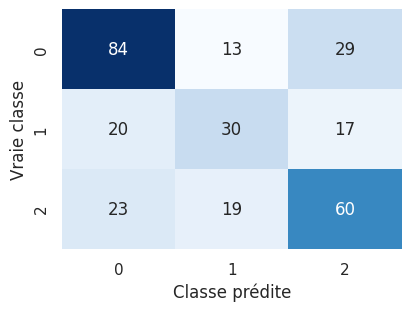

In [18]:
plot_confusion(outputs_test, outputs_mlp_test)

Le réseau fait nettement mieux que la régression logistique sur le test : 0.569 contre 0.499 de F1 macro. Les deux restent modestes : la méthode de contraception se prédit mal à partir de ces neuf variables. La matrice de confusion montre que la classe 1, les méthodes de longue durée, est la plus difficile : seules 30 femmes sur 67 sont bien classées.

### 6. La sauvegarde

In [19]:
weights_path = data_path / "mlp_contraception.pt"
torch.save(chosen_model.state_dict(), weights_path)

loaded_model = MLP(n_inputs=n_inputs, n_hidden=64, n_classes=3).to(device)
loaded_model.load_state_dict(torch.load(weights_path, weights_only=True))
_, outputs_loaded_test = evaluate(loaded_model, test_loader, loss_fn)
print((outputs_loaded_test == outputs_mlp_test).all())

True
